# 음식 분류기 학습 결과 시각화

AIHub 122 음식분류 이미지(109종)로 학습한 분류기(`n296/food_classifier.py`)의 결과를 본다.
파이프라인(`n296/pipeline_infer.py`)은 이 분류기의 확신도가 **0.7 미만이면 Gemini** 로 음식명을 다시 예측한다.

1. 데이터 구성
2. 학습 곡선
3. 확신도 기준(threshold)별 분류기 사용 비율과 정확도
4. 확신도 보정 (reliability diagram)
5. 음식별·대분류별 정확도
6. 자주 헷갈리는 음식
7. 분류기가 모르는 음식(test_dataset_296)에서의 확신도
8. 예측 예시
9. 파이프라인 스모크 테스트 결과

그림은 `runs/food_cls_122/figures/` 에도 PNG 로 저장한다.

In [1]:
import os, sys, json
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
ROOT = "/home/students/cs/202321024/2025_2/diet-management/n296_stage3"
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, matplotlib as mpl
from pathlib import Path
from PIL import Image
from torch.utils.data import DataLoader
from IPython.display import display

from n296.common import load_config, resolve
from n296.food_classifier import FoodClassifier, FoodDataset, eval_transform, predict_logits, calibration_report

load_config("configs/aihub122.yaml")
RUN = resolve("runs/food_cls_122")
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)

# 차트 스타일: 표면·잉크·계열 색 (dataviz 기본 팔레트)
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e8e7e3"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"   # 계열 1·2·3 (파랑·주황·청록)
mpl.rcParams.update({
    "font.family": "Noto Sans CJK JP", "axes.unicode_minus": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.axisbelow": True, "axes.titlelocation": "left", "lines.linewidth": 2, "figure.dpi": 110,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

CATS = {"02": "면류", "03": "죽", "05": "찜", "09": "조림", "10": "튀김"}
report = json.loads((RUN / "report.json").read_text())
split = pd.read_csv(resolve("data/food_cls_122/split.csv"), dtype={"code": str})
split["category"] = split["code"].str[:2].map(CATS)
print("best epoch", report["best_epoch"], "| temperature", round(report["temperature"], 3))

best epoch 28 | temperature 0.822


## 1. 데이터 구성

사진 파일명 끝 `_0/_1` 만 다른 것을 한 그룹으로 묶어 train/val/test = 8:1:1 로 나눴다.

In [2]:
tab = split.pivot_table(index="category", columns="split", values="path", aggfunc="size")[["train", "val", "test"]]
tab["음식 종류"] = split.groupby("category")["code"].nunique()
tab.loc["합계"] = tab.sum()
display(tab)

split,train,val,test,음식 종류
category,,,,
면류,6843,856,847,43
조림,3192,404,396,20
죽,2061,263,259,13
찜,1999,257,256,13
튀김,3126,386,394,20
합계,17221,2166,2152,109


## 2. 학습 곡선

두 값은 단위가 달라 한 축에 겹치지 않고 나란히 그린다. 가장 좋은 검증 정확도의 epoch 를 표시했다.

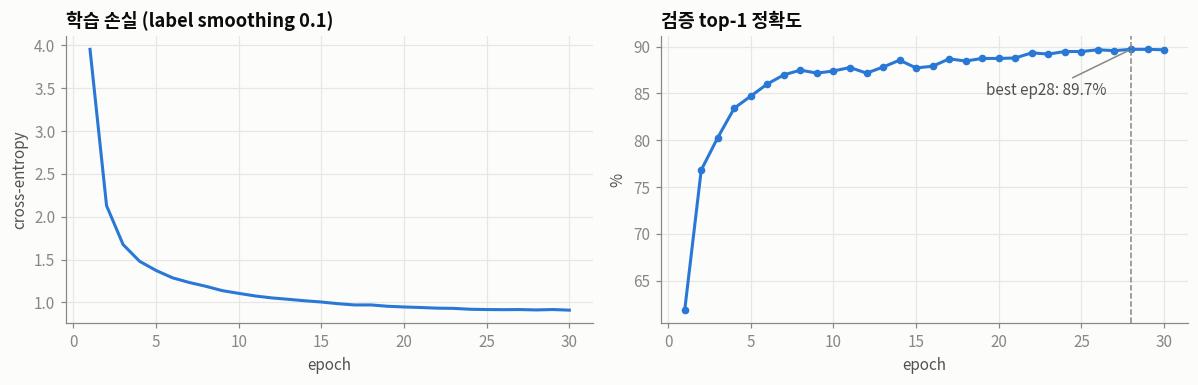

In [3]:
h = pd.DataFrame(report["history"])
best = report["best_epoch"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h.epoch, h.train_loss, color=C1)
ax[0].set(title="학습 손실 (label smoothing 0.1)", xlabel="epoch", ylabel="cross-entropy")
ax[1].plot(h.epoch, h.val_top1 * 100, color=C1, marker="o", markersize=4)
ax[1].axvline(best, color=MUTED, ls="--", lw=1)
bv = h.loc[h.epoch == best, "val_top1"].item() * 100
ax[1].annotate(f"best ep{best}: {bv:.1f}%", (best, bv), xytext=(-95, -30), textcoords="offset points",
               color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax[1].set(title="검증 top-1 정확도", xlabel="epoch", ylabel="%")
fig.tight_layout(); save(fig, "01_learning_curve"); plt.show()

## 3. 확신도 기준별 결과 (test 2,152장)

테스트셋을 다시 예측해 logit 을 얻는다. 확신도는 temperature 로 보정한 softmax 최댓값이다.

In [4]:
clf = FoodClassifier(RUN / "best.pth", "cuda")
T = clf.temperature
class_idx = {c: i for i, (c, _) in enumerate(clf.classes)}
names = [n for _, n in clf.classes]
test = split[split.split == "test"].reset_index(drop=True)
loader = DataLoader(FoodDataset(test, class_idx, eval_transform(288)), batch_size=128, num_workers=8)
logits, labels = predict_logits(clf.model, loader, torch.device("cuda"))
prob = F.softmax(logits / T, 1)
conf, pred = prob.max(1)
correct = (pred == labels).numpy()
conf = conf.numpy()
print(f"test top1 {correct.mean():.4f}")

test top1 0.8885


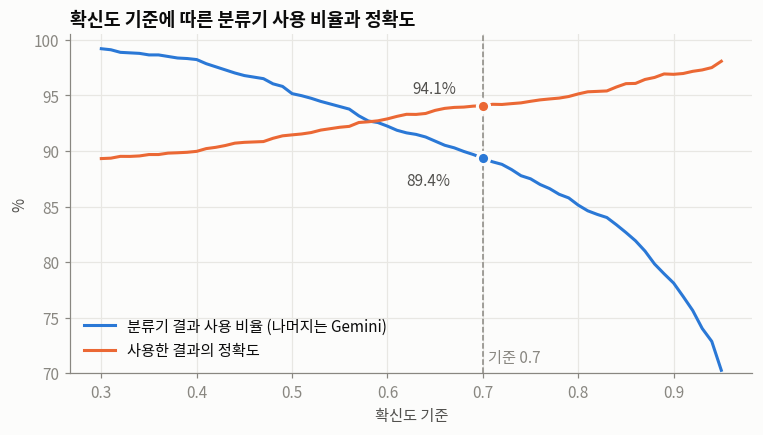

,분류기 사용 %,정확도 %,Gemini 로 %
기준,,,
0.5,95.2,91.5,4.8
0.6,92.2,92.9,7.8
0.7,89.4,94.1,10.6
0.8,85.1,95.1,14.9
0.9,78.1,96.9,21.9


In [5]:
th = np.round(np.arange(0.30, 0.96, 0.01), 2)
cov = np.array([(conf >= t).mean() for t in th])
acc = np.array([correct[conf >= t].mean() for t in th])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(th, cov * 100, color=C1, label="분류기 결과 사용 비율 (나머지는 Gemini)")
ax.plot(th, acc * 100, color=C2, label="사용한 결과의 정확도")
ax.axvline(0.7, color=MUTED, ls="--", lw=1)
i = int(np.where(th == 0.7)[0][0])
for y, c, off in ((cov[i], C1, (-50, -18)), (acc[i], C2, (-46, 8))):
    ax.plot(0.7, y * 100, "o", color=c, ms=8, mec=SURFACE, mew=2)
    ax.annotate(f"{y*100:.1f}%", (0.7, y * 100), xytext=off, textcoords="offset points", color=INK2)
ax.text(0.705, 71, "기준 0.7", color=MUTED)
ax.set(title="확신도 기준에 따른 분류기 사용 비율과 정확도", xlabel="확신도 기준", ylabel="%", ylim=(70, 100.5))
ax.legend(loc="lower left", frameon=False)
save(fig, "02_threshold_tradeoff"); plt.show()
display(pd.DataFrame({"기준": th, "분류기 사용 %": cov * 100, "정확도 %": acc * 100, "Gemini 로 %": (1 - cov) * 100})
        .query("기준 in [0.5, 0.6, 0.7, 0.8, 0.9]").round(1).set_index("기준"))

## 4. 확신도 보정

대각선에 가까울수록 확신도가 실제 정답률과 맞는다. 보정 전(T=1)과 val 로 맞춘 temperature 를 적용한 보정 후를 비교한다.

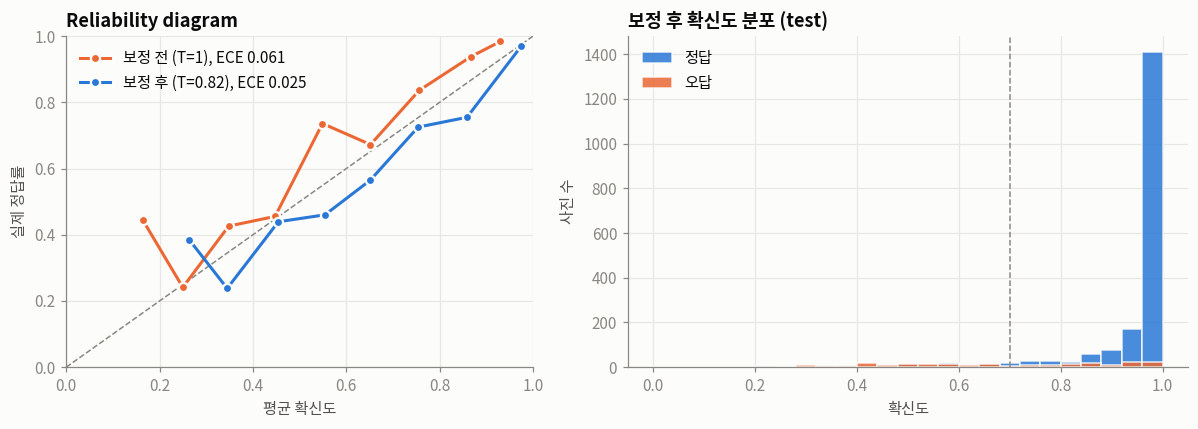

In [6]:
def reliability(p, n_bins=10):
    c, pr = p.max(1)
    ok = (pr == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    xs, ys, ns = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (c > lo) & (c <= hi)
        if m.sum() >= 5:
            xs.append(float(c[m].mean())); ys.append(float(ok[m].mean())); ns.append(int(m.sum()))
    return np.array(xs), np.array(ys), np.array(ns)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.2]})
ax[0].plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
for T_, c, lab in ((1.0, C2, "보정 전 (T=1)"), (T, C1, f"보정 후 (T={T:.2f})")):
    x, y, _ = reliability(F.softmax(logits / T_, 1))
    ece = calibration_report(logits, labels, T_)["ece"]
    ax[0].plot(x, y, "o-", color=c, ms=6, mec=SURFACE, mew=1.5, label=f"{lab}, ECE {ece:.3f}")
ax[0].set(title="Reliability diagram", xlabel="평균 확신도", ylabel="실제 정답률", xlim=(0, 1), ylim=(0, 1))
ax[0].legend(frameon=False, loc="upper left")
bins = np.linspace(0, 1, 26)
ax[1].hist(conf[correct == 1], bins=bins, color=C1, alpha=0.85, label="정답", edgecolor=SURFACE, lw=1)
ax[1].hist(conf[correct == 0], bins=bins, color=C2, alpha=0.85, label="오답", edgecolor=SURFACE, lw=1)
ax[1].axvline(0.7, color=MUTED, ls="--", lw=1)
ax[1].set(title="보정 후 확신도 분포 (test)", xlabel="확신도", ylabel="사진 수")
ax[1].legend(frameon=False)
fig.tight_layout(); save(fig, "03_calibration"); plt.show()

## 5. 음식별·대분류별 정확도 (test)

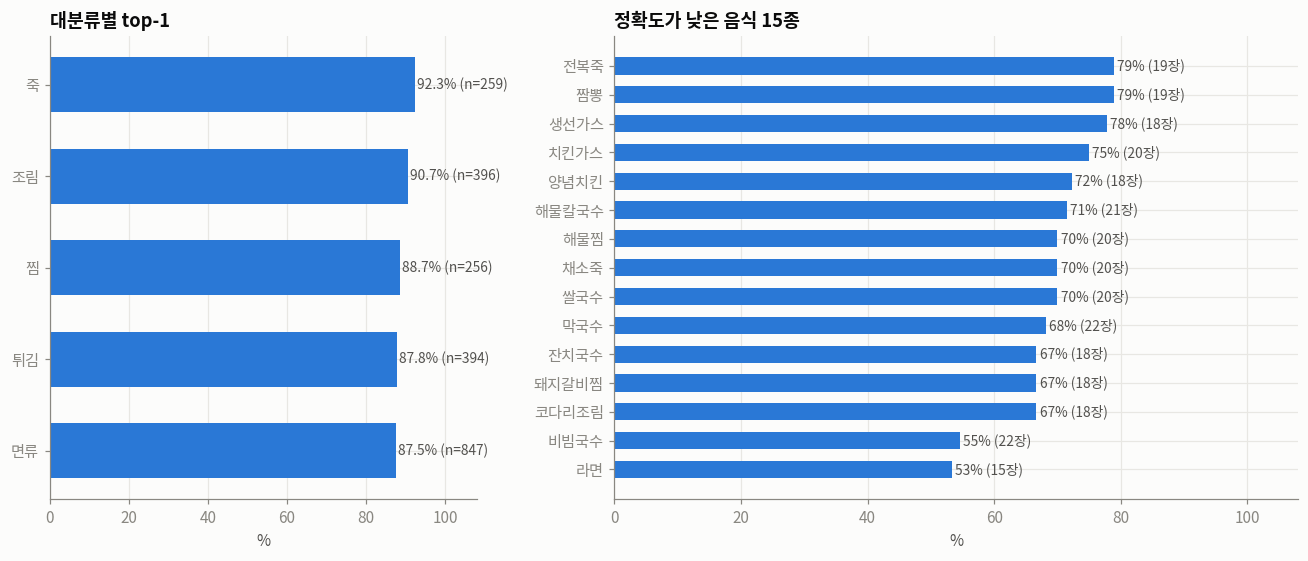

음식 109종 중 정확도 100%: 22종, 80% 미만: 16종


In [7]:
t = test.assign(correct=correct, pred=[names[i] for i in pred.numpy()])
cat = t.groupby("category")["correct"].agg(["mean", "size"]).sort_values("mean")
per = t.groupby(["code", "name"])["correct"].agg(["mean", "size"]).reset_index().sort_values("mean")
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].barh(cat.index, cat["mean"] * 100, color=C1, height=0.6)
for y, (m, n) in enumerate(cat.values):
    ax[0].text(m * 100 + 0.5, y, f"{m*100:.1f}% (n={int(n)})", va="center", color=INK2, fontsize=9)
ax[0].set(title="대분류별 top-1", xlim=(0, 108), xlabel="%")
low = per.head(15)
ax[1].barh(low["name"], low["mean"] * 100, color=C1, height=0.6)
for y, (m, n) in enumerate(low[["mean", "size"]].values):
    ax[1].text(m * 100 + 0.5, y, f"{m*100:.0f}% ({int(n)}장)", va="center", color=INK2, fontsize=9)
ax[1].set(title="정확도가 낮은 음식 15종", xlim=(0, 108), xlabel="%")
fig.tight_layout(); save(fig, "04_per_class"); plt.show()
print(f"음식 {len(per)}종 중 정확도 100%: {(per['mean'] == 1).sum()}종, 80% 미만: {(per['mean'] < 0.8).sum()}종")

## 6. 자주 헷갈리는 음식 (test 오답 쌍 상위 15)

In [8]:
wrong = t[t.correct == 0]
pairs = wrong.groupby(["name", "pred"]).size().rename("오답 수").reset_index().sort_values("오답 수", ascending=False)
pairs.columns = ["정답", "예측", "오답 수"]
display(pairs.head(15).reset_index(drop=True))

,정답,예측,오답 수
0,비빔국수,쫄면,6
1,막국수,물냉면,4
2,라면,짬뽕라면,4
3,메밀국수,막국수,3
4,만둣국,떡만둣국,3
5,닭튀김,탕수육,3
6,김치말이국수,잔치국수,3
7,짬뽕,삼선짬뽕,3
8,치즈돈가스,치킨가스,3
9,돼지갈비찜,소갈비찜,3


## 7. 분류기가 모르는 음식에서의 확신도

`test_dataset_296` 의 19종은 **모두** 분류기 109종에 없다. 이상적으로는 확신도가 낮아 전부 Gemini 로 넘어가야 한다.
확신도 0.7 이상이면 틀린(또는 상위 범주) 음식명이 Gemini 를 거치지 않고 그대로 쓰인다.

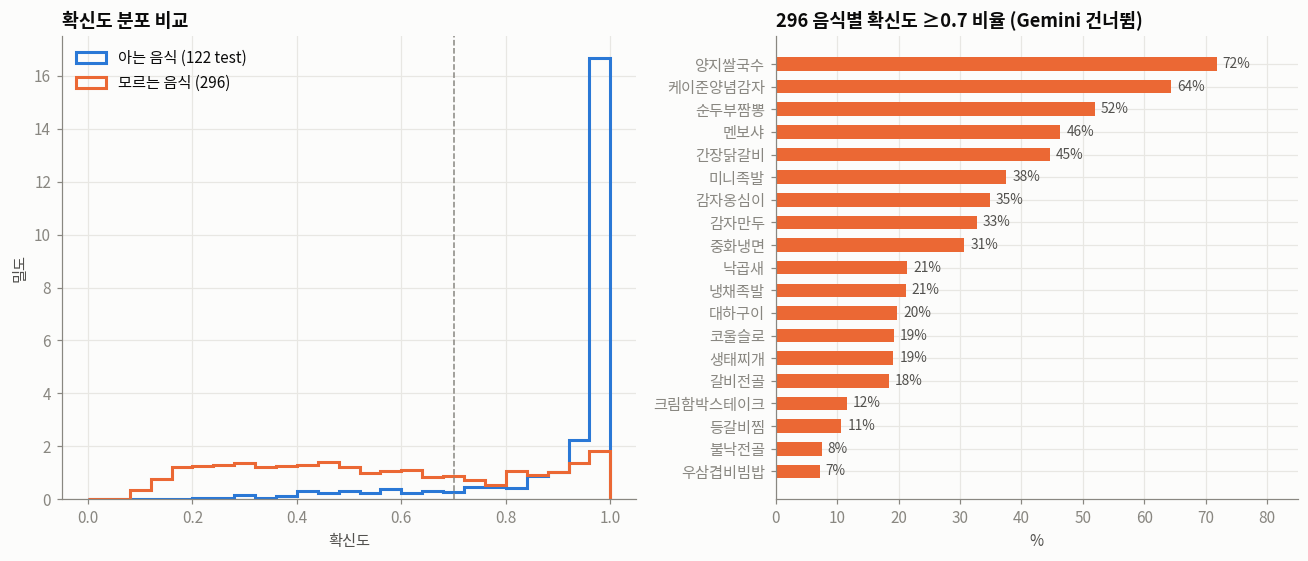

296 전체 2664장 중 확신도 ≥0.7: 31.9%  |  122 test: 89.4%


,실제 음식(296),분류기 예측,장수
0,양지쌀국수,쌀국수,151
1,케이준양념감자,감자튀김,63
2,멘보샤,두부고추장조림,35
3,중화냉면,굴짬뽕,35
4,순두부짬뽕,토마토스프,32
5,간장닭갈비,깐풍기,25
6,미니족발,족발,24
7,감자만두,고기만두,22
8,대하구이,꽁치조림,21
9,멘보샤,고구마맛탕,20


In [9]:
ood = pd.read_csv(RUN / "ood_test296.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
bins = np.linspace(0, 1, 26)
ax[0].hist(conf, bins=bins, density=True, histtype="step", lw=2, color=C1, label="아는 음식 (122 test)")
ax[0].hist(ood["prob"], bins=bins, density=True, histtype="step", lw=2, color=C2, label="모르는 음식 (296)")
ax[0].axvline(0.7, color=MUTED, ls="--", lw=1)
ax[0].set(title="확신도 분포 비교", xlabel="확신도", ylabel="밀도")
ax[0].legend(frameon=False, loc="upper left")
s = ood.groupby("gt")["prob"].apply(lambda x: (x >= 0.7).mean()).sort_values()
ax[1].barh(s.index, s.values * 100, color=C2, height=0.6)
for y, v in enumerate(s.values):
    ax[1].text(v * 100 + 1, y, f"{v*100:.0f}%", va="center", color=INK2, fontsize=9)
ax[1].set(title="296 음식별 확신도 ≥0.7 비율 (Gemini 건너뜀)", xlabel="%", xlim=(0, 85))
fig.tight_layout(); save(fig, "05_ood_296"); plt.show()
print(f"296 전체 {len(ood)}장 중 확신도 ≥0.7: {(ood.prob >= 0.7).mean()*100:.1f}%  |  122 test: {(conf >= 0.7).mean()*100:.1f}%")
top = ood[ood.prob >= 0.7].groupby(["gt", "pred"]).size().rename("장수").reset_index().sort_values("장수", ascending=False)
top.columns = ["실제 음식(296)", "분류기 예측", "장수"]
display(top.head(12).reset_index(drop=True))

## 8. 예측 예시

위: 맞힌 사진 / 가운데: 확신도가 높은데 틀린 사진 / 아래: 모르는 음식(296)인데 확신도 ≥0.7

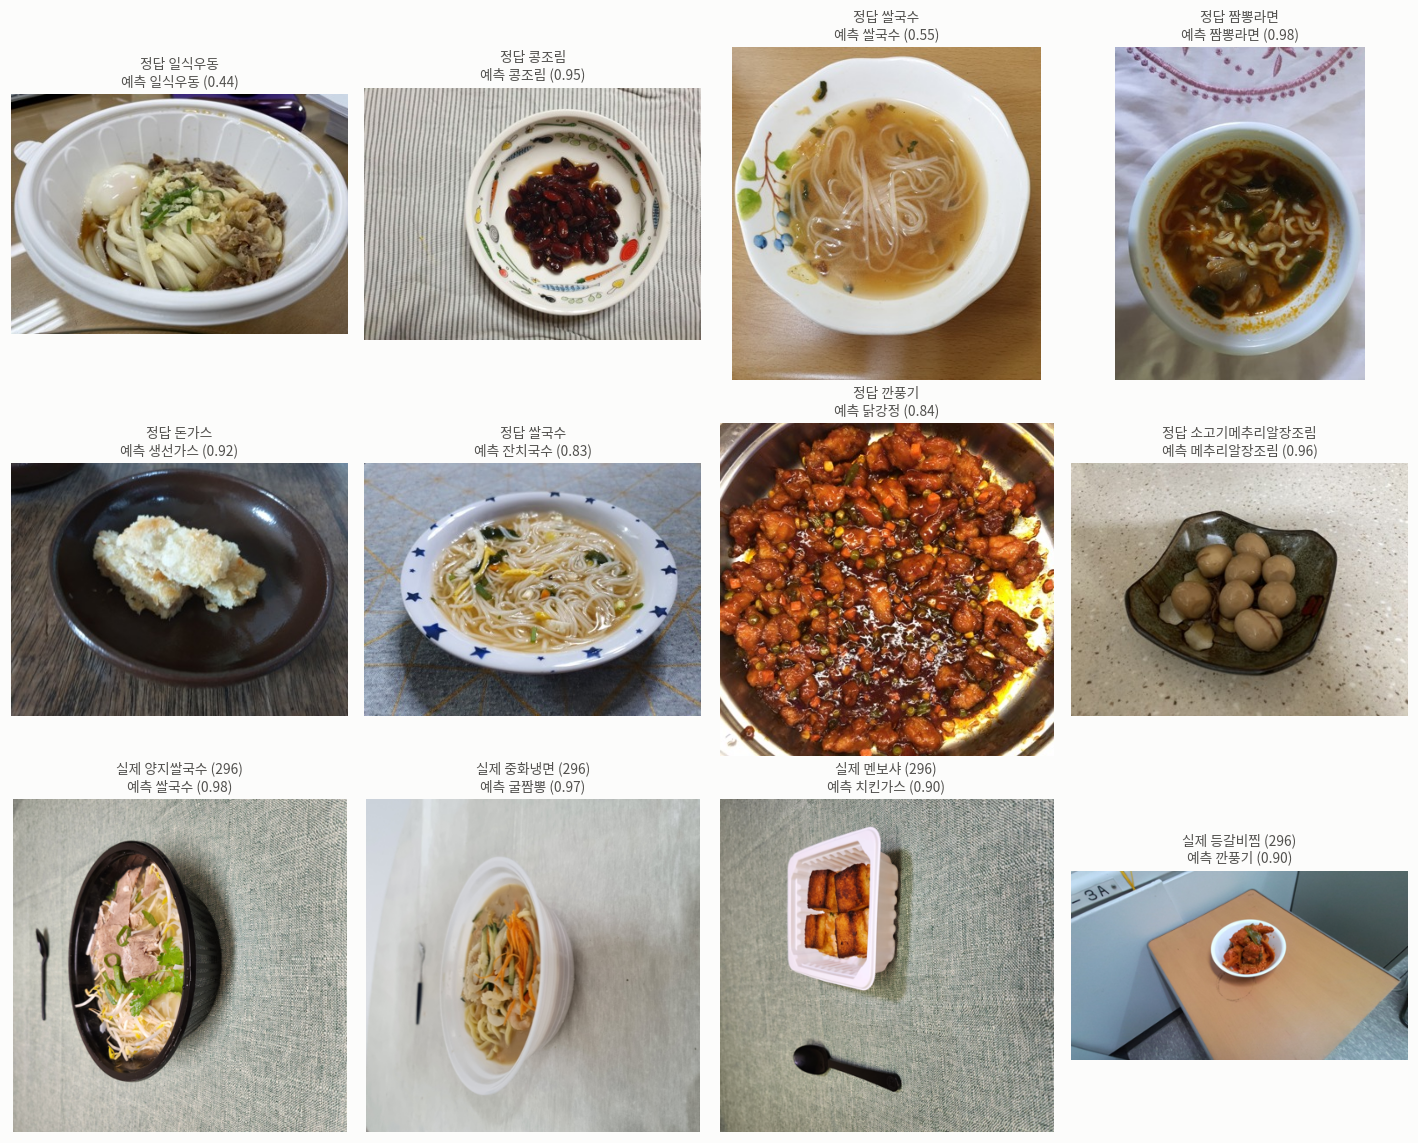

In [10]:
rng = np.random.default_rng(0)
def pick(df, n=4):
    return df.iloc[rng.choice(len(df), min(n, len(df)), replace=False)]
t["conf"] = conf
ex = [
    [(r.path, f"정답 {r['name']}\n예측 {r.pred} ({r.conf:.2f})") for _, r in pick(t[(t.correct == 1)]).iterrows()],
    [(r.path, f"정답 {r['name']}\n예측 {r.pred} ({r.conf:.2f})") for _, r in pick(t[(t.correct == 0) & (t.conf >= 0.7)]).iterrows()],
]
IMG296 = "/home/students/cs/202321024/datasets/test_dataset_296/images/"
m296 = pd.read_csv("/home/students/cs/202321024/datasets/test_dataset_296/test_manifest.csv")
ood["file"] = m296["image_path"].str.split("/").str[-1].values
ex.append([(IMG296 + r.file, f"실제 {r['gt']} (296)\n예측 {r.pred} ({r.prob:.2f})") for _, r in pick(ood[ood.prob >= 0.7]).iterrows()])
fig, axes = plt.subplots(3, 4, figsize=(13, 10.5))
for row, items in zip(axes, ex):
    for a, (p, title) in zip(row, items):
        im = Image.open(p).convert("RGB"); im.thumbnail((400, 400))
        a.imshow(im); a.set_title(title, fontsize=9, loc="center", fontweight="normal", color=INK2); a.axis("off")
fig.tight_layout(); save(fig, "06_examples"); plt.show()

## 9. 파이프라인 스모크 테스트

`runs/pipeline_smoke2`: 음식명 → 재료 → 임베딩 → 영양 예측까지 동작 확인용 2장. 영양 값은 원본 체크포인트의 출력 단위를 몰라(`--raw-output`) 의미가 없다.

In [11]:
r = pd.read_json(resolve("runs/pipeline_smoke2/pipeline_results.json"))
r["image"] = r["image_path"].str.split("/").str[-1]
display(r[["image", "cls_name", "cls_prob", "name_source", "food_name", "ingredients", "pred_calories"]].round(2))

,image,cls_name,cls_prob,name_source,food_name,ingredients,pred_calories
0,10_102_10012003_160678781933652_0.jpg,돈가스,0.69,gemini,돈가스,"[돼지고기, 밀가루, 달걀, 빵가루, 식용유]",2.02
1,A_13_A13010_대하구이_02_01.jpg,꽁치조림,0.23,gemini,새우구이,"[새우, 소금]",2.29
